# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión B

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** José Alberto Vargas Chávez
**Grupo:** 512  **Fecha:** 26/10/26

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la cantidad de pasajeros y la distancia recorrida?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`passenger_count`** y **`trip_distance`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_B_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_B/
└── notebooks/
    └── Examen_B_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

> **Nota de ejecución local:** se conserva arriba la consigna original. En esta carpeta el CSV está en `Examen/nyc_taxi_examen.csv`; por ello, el código ejecutado utiliza `../nyc_taxi_examen.csv` desde `notebooks/`. La estructura de datos local difiere de la solicitada en el enunciado.


## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
FEATURES = ["passenger_count", "trip_distance"]
DATA_PATH = Path("../nyc_taxi_examen.csv")
OUTPUT_PATH = Path("../data/processed/nyc_taxi_cash_clusters.csv")

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"No se encontró {DATA_PATH}. Ejecuta desde notebooks/.")

# La primera columna del CSV es el índice exportado, no una variable del viaje.
df = pd.read_csv(DATA_PATH, index_col=0)
required_columns = set(FEATURES + ["payment_type", "fare_amount", "trip_duration"])
if missing_columns := required_columns.difference(df.columns):
    raise ValueError(f"Faltan columnas requeridas: {sorted(missing_columns)}")

print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
display(df.head())
display(df.dtypes.rename("tipo_de_dato").to_frame())
display(df.describe())
display(df["payment_type"].value_counts(dropna=False).rename("viajes").to_frame())

Matplotlib is building the font cache; this may take a moment.


Dimensiones: 2,427,612 filas × 20 columnas


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,Credit card,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,Credit card,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,Credit card,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


,tipo_de_dato
VendorID,int64
tpep_pickup_datetime,str
tpep_dropoff_datetime,str
passenger_count,float64
trip_distance,float64
RatecodeID,float64
PULocationID,float64
DOLocationID,float64
payment_type,str
fare_amount,float64


,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2.427612e+06,2.415489e+06,2.415470e+06,2.415474e+06,2.415487e+06,2.415475e+06,2.415488e+06,2.415487e+06,2.415462e+06,2.415459e+06,2.415465e+06,2.415481e+06,2.415484e+06,2.415457e+06,2.415481e+06,2.415462e+06,2.415475e+06
mean,1.888167e+00,1.296144e+00,3.300702e+00,4.229419e+00,1.641392e+02,1.632236e+02,3.852567e+01,1.567837e+00,4.849912e-01,3.665195e+00,5.938668e-01,9.873437e-01,2.937731e+01,2.254823e+00,1.979527e-01,5.625318e-01,1.561446e+01
std,8.086844e-01,1.881923e+00,5.167909e+00,1.720220e+01,6.285386e+01,6.925613e+01,5.423764e+02,1.906552e+00,1.018682e-01,4.234050e+00,2.385704e+00,1.560490e-01,2.592570e+01,7.815658e-01,6.259005e-01,3.314852e-01,2.605773e+02
min,1.000000e+00,-5.000000e+00,-9.998763e+01,1.000000e+00,1.000000e+00,1.000000e+00,-1.849600e+03,-7.500000e+00,-5.000000e-01,-9.000000e+01,-1.064600e+02,-1.000000e+00,-1.866890e+03,-2.500000e+00,-2.000000e+00,-7.500000e-01,-3.005175e+05
25%,2.000000e+00,1.000000e+00,9.900000e-01,1.000000e+00,1.320000e+02,1.130000e+02,9.300000e+00,0.000000e+00,5.000000e-01,1.000000e+00,0.000000e+00,1.000000e+00,1.638000e+01,2.500000e+00,0.000000e+00,7.500000e-01,7.283333e+00
50%,2.000000e+00,1.000000e+00,1.700000e+00,1.000000e+00,1.610000e+02,1.620000e+02,1.350000e+01,1.000000e+00,5.000000e-01,2.950000e+00,0.000000e+00,1.000000e+00,2.154000e+01,2.500000e+00,0.000000e+00,7.500000e-01,1.231667e+01
75%,2.000000e+00,1.000000e+00,3.360000e+00,1.000000e+00,2.320000e+02,2.340000e+02,2.190000e+01,2.500000e+00,5.000000e-01,4.560000e+00,0.000000e+00,1.000000e+00,3.145000e+01,2.500000e+00,0.000000e+00,7.500000e-01,2.011667e+01
max,7.000000e+00,1.000000e+02,1.686490e+03,9.900000e+01,2.650000e+02,2.650000e+02,1.999559e+04,2.325000e+01,1.150000e+01,4.444400e+02,6.167900e+02,1.000000e+00,5.530740e+03,2.750000e+00,2.700000e+01,7.500000e-01,8.373667e+03


,viajes
payment_type,
Credit card,2051983
Cash,329533
Dispute,23558
NaN,12125
No charge,10413


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [2]:
df_limpio = df.copy()
print("Dimensiones antes de limpiar:", df_limpio.shape)
display(df_limpio.isna().sum().rename("nulos_antes").to_frame())
duplicados = int(df_limpio.duplicated().sum())
print(f"Registros duplicados (sin considerar el índice exportado): {duplicados:,}")

n_original = len(df_limpio)
df_limpio = df_limpio.drop_duplicates()
n_sin_duplicados = len(df_limpio)
df_limpio = df_limpio.dropna()
n_sin_nulos = len(df_limpio)

condiciones_validas = (
    df_limpio["trip_distance"].gt(0)
    & df_limpio["passenger_count"].gt(0)
    & df_limpio["passenger_count"].lt(100)
    & df_limpio["fare_amount"].gt(0)
    & df_limpio["fare_amount"].lt(10000)
    & df_limpio["trip_duration"].gt(0)
)
df_limpio = df_limpio.loc[condiciones_validas].copy()

display(pd.DataFrame({
    "etapa": ["Original", "Sin duplicados", "Sin nulos", "Condiciones válidas"],
    "filas": [n_original, n_sin_duplicados, n_sin_nulos, len(df_limpio)],
}))
print("Dimensiones después de limpiar:", df_limpio.shape)
print(f"Registros eliminados en total: {n_original - len(df_limpio):,}")

Dimensiones antes de limpiar: (2427612, 20)


,nulos_antes
VendorID,0
tpep_pickup_datetime,12126
tpep_dropoff_datetime,12127
passenger_count,12123
trip_distance,12142
RatecodeID,12138
PULocationID,12125
DOLocationID,12137
payment_type,12125
fare_amount,12124


Registros duplicados (sin considerar el índice exportado): 11,961


,etapa,filas
0,Original,2427612
1,Sin duplicados,2415651
2,Sin nulos,2196158
3,Condiciones válidas,2096600


Dimensiones después de limpiar: (2096600, 20)
Registros eliminados en total: 331,012


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`passenger_count`** y **`trip_distance`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [3]:
df_cash = df_limpio.loc[df_limpio["payment_type"].eq("Cash")].copy()
X = df_cash.loc[:, FEATURES].copy()

if len(X) <= 6:
    raise ValueError("Se requieren más de seis viajes para evaluar k de 2 a 6.")
print(f"Viajes pagados exactamente como 'Cash': {len(df_cash):,}")
display(X.describe())

Viajes pagados exactamente como 'Cash': 282,085


,passenger_count,trip_distance
count,282085.000000,282085.000000
mean,1.343882,3.842165
std,0.759067,6.214391
min,1.000000,0.010000
25%,1.000000,0.920000
50%,1.000000,1.700000
75%,1.000000,4.370000
max,6.000000,1686.490000


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [4]:
X_log = np.log1p(X)
scaler = StandardScaler()
X_escalado = pd.DataFrame(
    scaler.fit_transform(X_log), columns=FEATURES, index=X.index
)

print("Variables transformadas con log1p:")
display(X_log.describe())
print("Variables transformadas y estandarizadas:")
display(X_escalado.describe())
display(pd.DataFrame({
    "media": X_escalado.mean(),
    "desviacion_poblacional": X_escalado.std(ddof=0),
}))
# StandardScaler utiliza la desviación poblacional; describe() usa ddof=1.
assert np.isfinite(X_escalado.to_numpy()).all()
assert np.allclose(X_escalado.mean(), 0, atol=1e-10)
assert np.allclose(X_escalado.std(ddof=0), 1, atol=1e-10)

Variables transformadas con log1p:


,passenger_count,trip_distance
count,282085.000000,282085.000000
mean,0.814772,1.225454
std,0.250268,0.763298
min,0.693147,0.009950
25%,0.693147,0.652325
50%,0.693147,0.993252
75%,0.693147,1.680828
max,1.945910,7.430997


Variables transformadas y estandarizadas:


,passenger_count,trip_distance
count,2.820850e+05,2.820850e+05
mean,-2.651894e-16,2.111842e-16
std,1.000002e+00,1.000002e+00
min,-4.859776e-01,-1.592439e+00
25%,-4.859776e-01,-7.508596e-01
50%,-4.859776e-01,-3.042097e-01
75%,-4.859776e-01,5.965880e-01
max,4.519712e+00,8.129920e+00


,media,desviacion_poblacional
passenger_count,-2.651894e-16,1.0
trip_distance,2.111842e-16,1.0


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

,k,Inercia,Silueta
0,2,324581.9399,0.5503
1,3,160363.1884,0.6117
2,4,115075.5831,0.6202
3,5,86895.8983,0.6249
4,6,61144.8891,0.5617


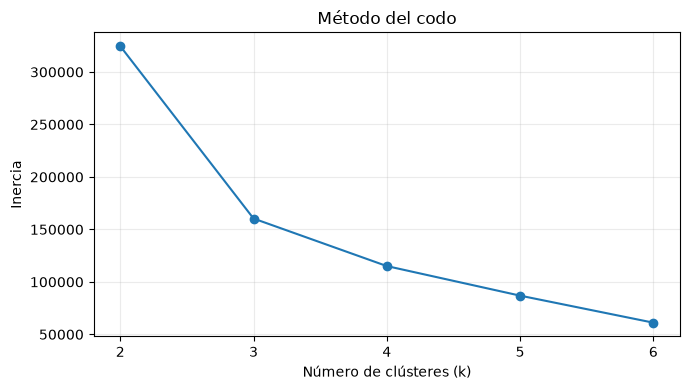

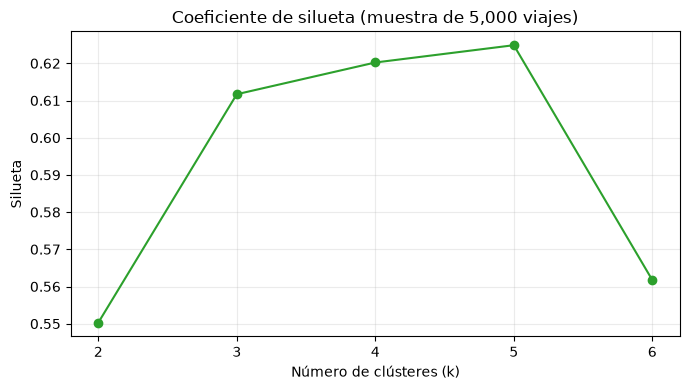

In [5]:
metricas = []
for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)
    silueta = silhouette_score(
        X_escalado, etiquetas, sample_size=5000, random_state=RANDOM_STATE
    )
    metricas.append({"k": k, "Inercia": modelo.inertia_, "Silueta": silueta})

comparacion = pd.DataFrame(metricas)
display(comparacion.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(comparacion["k"], comparacion["Inercia"], marker="o")
ax.set(title="Método del codo", xlabel="Número de clústeres (k)", ylabel="Inercia")
ax.set_xticks(comparacion["k"])
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(comparacion["k"], comparacion["Silueta"], marker="o", color="tab:green")
ax.set(title="Coeficiente de silueta (muestra de 5,000 viajes)",
       xlabel="Número de clústeres (k)", ylabel="Silueta")
ax.set_xticks(comparacion["k"])
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`passenger_count`**, eje Y = **`trip_distance`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

k seleccionado: 5


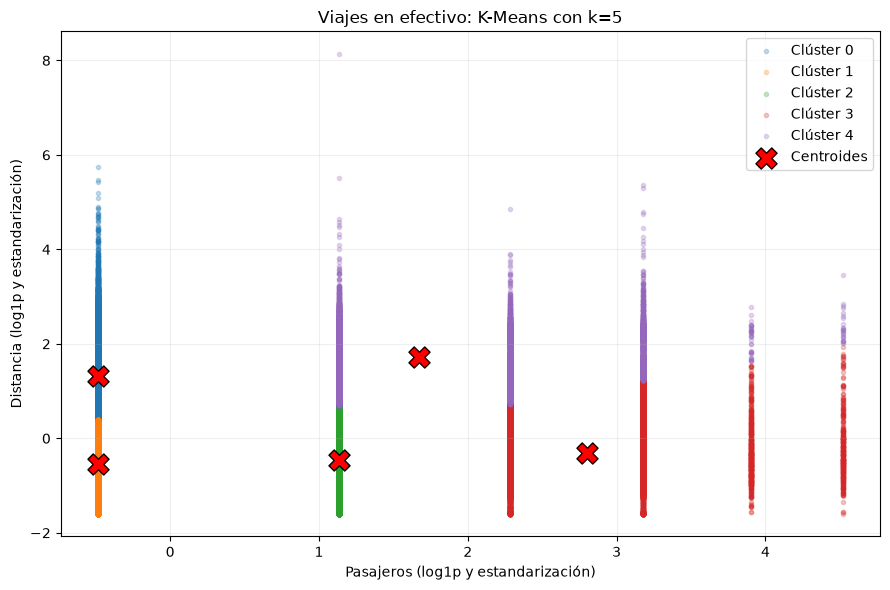

In [6]:
# Se prioriza la mayor silueta entre los k evaluados; se discute junto
# con la inercia y los perfiles en las respuestas finales.
k_elegido = int(comparacion.loc[comparacion["Silueta"].idxmax(), "k"])
modelo_final = KMeans(n_clusters=k_elegido, random_state=RANDOM_STATE, n_init=10)
etiquetas_finales = modelo_final.fit_predict(X_escalado)
print(f"k seleccionado: {k_elegido}")

fig, ax = plt.subplots(figsize=(9, 6))
colores = plt.get_cmap("tab10")
for cluster in range(k_elegido):
    puntos = X_escalado.loc[etiquetas_finales == cluster]
    ax.scatter(puntos["passenger_count"], puntos["trip_distance"],
               s=9, alpha=0.25, color=colores(cluster), label=f"Clúster {cluster}",
               rasterized=True)
centroides = modelo_final.cluster_centers_
ax.scatter(centroides[:, 0], centroides[:, 1], marker="X", s=230,
           color="red", edgecolors="black", linewidths=1, label="Centroides")
ax.set(title=f"Viajes en efectivo: K-Means con k={k_elegido}",
       xlabel="Pasajeros (log1p y estandarización)",
       ylabel="Distancia (log1p y estandarización)")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `passenger_count`.
   - **Media y mediana** de `trip_distance`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: número de pasajeros y millas para la distancia.

**Evidencia:** tabla de estadísticos por clúster.

In [7]:
df_resultado = df_cash.copy()
# Las etiquetas conservan exactamente el orden de las filas usadas al ajustar.
assert X_escalado.index.equals(df_resultado.index)
df_resultado["cluster"] = etiquetas_finales

resumen_clusters = df_resultado.groupby("cluster").agg(
    cantidad_viajes=("cluster", "size"),
    pasajeros_media=("passenger_count", "mean"),
    pasajeros_mediana=("passenger_count", "median"),
    distancia_media_millas=("trip_distance", "mean"),
    distancia_mediana_millas=("trip_distance", "median"),
)
print("Estadísticos en unidades originales (pasajeros y millas):")
display(resumen_clusters.round(2))
assert resumen_clusters["cantidad_viajes"].sum() == len(df_cash)
assert df_resultado["cluster"].nunique() == k_elegido

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
df_resultado.to_csv(OUTPUT_PATH, index=False)
print(f"Dataset con etiquetas guardado en: {OUTPUT_PATH}")

Estadísticos en unidades originales (pasajeros y millas):


,cantidad_viajes,pasajeros_media,pasajeros_mediana,distancia_media_millas,distancia_mediana_millas
cluster,,,,,
0,60035,1.0,1.0,9.54,7.95
1,160283,1.0,1.0,1.36,1.20
2,28514,2.0,2.0,1.58,1.31
3,16904,3.6,4.0,1.97,1.48
4,16349,2.5,2.0,13.14,11.51


Dataset con etiquetas guardado en: ../data/processed/nyc_taxi_cash_clusters.csv


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:** Elegí **k = 5**. Su silueta es **0.6249**, la mayor de los cinco valores evaluados, y su inercia es **86,895.90**. Con k = 4, la silueta es 0.6202 y la inercia 115,075.58: pasar a cinco grupos reduce la inercia aproximadamente **24.49 %**, aunque la mejora de silueta es pequeña (**0.0046**). Con k = 6, la inercia sigue bajando a 61,144.89, pero la silueta cae a 0.5617; esa partición tiene menor separación según esta métrica.

El descenso más marcado de la curva ocurre entre k = 2 y k = 3; después continúa bajando, sin un codo único que obligue a elegir cinco. Por eso combino esa evidencia con la mayor silueta y con la interpretación de cinco perfiles por ocupación y distancia. k = 4 también sería una alternativa razonable si se priorizara una segmentación más sencilla. La silueta se estimó sobre 5,000 viajes con semilla fija; la pequeña ventaja frente a k = 4 no demuestra por sí sola estabilidad frente a otras muestras. El ajuste de K-Means sí utiliza todos los viajes en efectivo que superan la limpieza.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:** Los nombres describen perfiles relativos dentro de esta muestra. Los identificadores de clúster no tienen orden jerárquico.

| Clúster | Nombre descriptivo | Viajes | Pasajeros: media / mediana | Distancia en millas: media / mediana |
|---|---|---:|---:|---:|
| 0 | Un pasajero, trayectos largos | 60,035 | 1.00 / 1.00 | 9.54 / 7.95 |
| 1 | Un pasajero, trayectos cortos | 160,283 | 1.00 / 1.00 | 1.36 / 1.20 |
| 2 | Dos pasajeros, trayectos cortos | 28,514 | 2.00 / 2.00 | 1.58 / 1.31 |
| 3 | Mayor ocupación, trayectos predominantemente cortos | 16,904 | 3.60 / 4.00 | 1.97 / 1.48 |
| 4 | Varios pasajeros, trayectos largos | 16,349 | 2.50 / 2.00 | 13.14 / 11.51 |

El perfil más frecuente es el de un pasajero y distancia corta (clúster 1). Los clústeres 0 y 4 reúnen las mayores distancias típicas; el clúster 3 tiene la mayor ocupación promedio. En todos los grupos, la distancia media supera a la mediana: esto es consistente con una cola de recorridos largos que eleva el promedio. Se conservaron los valores extremos que cumplen las condiciones indicadas, sin recortes por percentiles; por eso conviene interpretar también las medianas.

**Pregunta 3 — Análisis sencillo.** ¿Qué diferencias encuentras entre los grupos con menor y mayor cantidad promedio de pasajeros? Apóyate en la tabla.

**Respuesta:** Hay dos grupos empatados en el menor promedio de pasajeros: los clústeres **0 y 1**, ambos con media y mediana de **1** pasajero. Aun así, sus distancias son muy distintas: el 0 tiene media de **9.54 millas** y mediana de **7.95**, mientras que el 1 tiene media de **1.36** y mediana de **1.20**. Sus tamaños son 60,035 y 160,283 viajes, respectivamente.

El clúster **3**, con **16,904 viajes**, tiene la mayor ocupación promedio: **3.60 pasajeros**, con mediana de **4**. Su distancia media es **1.97 millas** y su mediana **1.48**: superiores a las del clúster 1, pero inferiores a las del clúster 0. Por tanto, aumentar la ocupación no corresponde a un aumento uniforme de la distancia.

**Pregunta 4 — Análisis sencillo.** ¿Los viajes con más pasajeros son siempre los de mayor distancia? Explica qué muestran tus clústeres, sin asumir que todos los viajes se comportan igual.

**Respuesta:** **No.** El grupo de mayor ocupación media (clúster 3, **3.60 pasajeros**) recorre en promedio **1.97 millas**. En cambio, el grupo de mayor distancia media (clúster 4, **13.14 millas**) tiene una ocupación media menor, **2.50 pasajeros**. Incluso los viajes largos de un solo pasajero del clúster 0 promedian **9.54 millas**. Las medianas respaldan este contraste: **1.48**, **11.51** y **7.95 millas**, respectivamente.

Estos resultados describen tendencias de los grupos, no una regla para cada viaje ni una relación causal. Dentro de cada clúster puede existir variación; el número de pasajeros por sí solo no determina la distancia recorrida.


---
### Lista de verificación antes de entregar

- [x] Se muestran la carga, exploración, limpieza y filtrado.
- [x] Se utilizaron las **dos variables indicadas**.
- [x] Se aplicaron `log1p` y `StandardScaler`.
- [x] Se calcularon inercia y silueta para `k = 2...6`.
- [x] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [x] Se visualizan los clústeres y sus centroides.
- [x] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [x] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**

**Resultado de la verificación:** los ocho puntos cuentan con evidencia en las celdas ejecutadas y las respuestas. Se conservaron las siete celdas de código ejecutadas sin errores, la tabla de métricas, las dos gráficas de evaluación, la gráfica de clústeres con centroides y la tabla en unidades originales. Esta lista no evalúa la ubicación del CSV; la diferencia respecto a la ruta original está indicada en la nota de ejecución local.
